# Capitulo 1

Creciente popularidad de los métodos de ensamble al ser una opción poderosa para tratar el tradeoff entre complejidad y ajuste (fit vs. complexity / bias vs. variance).

Meta estudios como el de Randal S. Olson et al. (2018) muestran el éxito predictivo de estos modelos en conjuntos estructurados de datos sobre modelos individuales. Generalmente estos se combinan con feature engineering.

Formalmente un método de ensamble es un algortimo de machine learning el cual mejora el rendimiento de su predicción agregando predicciones de múltiples estimadores o modelos. En ese sentido se trata de un metaestimador.

El éxito de estos modelos está en la diversidad del ensamble, también conocido como complementariedad de modelos u ortogonalidad de modelos.

Veamos esto con un ejemplo, usemos el conjunto de datos sintéticos llamado Friedman-1, el cuál fue creado para explorar tareas de regresión múltiple.





In [ ]:
# Generamos un set de 500 datos, 15 características y un ruido gaussiano con desviación de 0.3

from sklearn.datasets import make_friedman1
X, y = make_friedman1(n_samples=500,
                      n_features=15,
                      noise = 0.3,
                      random_state= 23)

In [7]:
# Dividamos los datos en entrenamiento (67%) y prueba (33%)
# una regla común e útil es el principio de Pareto 80%-20%
# entrenaremos arboles con diferentes profundidades, empezando con d=1 hasta d=10
# repetimos el experimento k=5 veces y promediaremos los resultados (validació cruzada)

import numpy as np
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import ShuffleSplit
from sklearn.model_selection import validation_curve

#establecemos 5 diferentes particiones aleatorias entre entrenamiento y prueba

subsets = ShuffleSplit(n_splits=5,
                      test_size=0.33,
                      random_state=0)

# especificamos el modelo

model = DecisionTreeRegressor()

# para cada partición entrenamos arboles de diferentes profundidades
# posteriormente evaluamos el rendimiento sonbre test usando r2

trn_scores, tst_scores = validation_curve(estimator=model,
                                       X=X,
                                       y=y,
                                       param_name= 'max_depth',
                                       param_range= np.arange(1,11),
                                       cv=subsets,
                                       scoring= "r2")

# promediamos las puntuaciones de evaluación
mean_train_scores = np.mean(trn_scores, axis=1)
mean_test_scores = np.mean(tst_scores, axis=1)

In [8]:
# Configurramos una fuente base para todos los gráficos

import matplotlib.pyplot as plt

# Configuración global para estilo de artículo científico
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = [
    'Times New Roman',
    'Times',
    'Nimbus Roman',
    'DejaVu Serif',
]
plt.rcParams['font.size'] = 9  # Tamaño de fuente global
plt.rcParams['axes.titlesize'] = 9
plt.rcParams['axes.labelsize'] = 9

Nuestro objetivo es construir un modelo que generalice adecuadamente, es decir, que tenga un buen rendimiento con datos inobservados.Intuitivamente puede considerarse que el objetivo implica entrenar modelos con el menoer error, lo que generalmente implica un modelo complejo, al requerir ajustarse a las diferentes observaciones.

Esta intuición lleva alsobreajuste del modelo, esto es, modelos con baja capacidad de generalización, aún cuando exhiben un bajo error en elentrenamiento.  

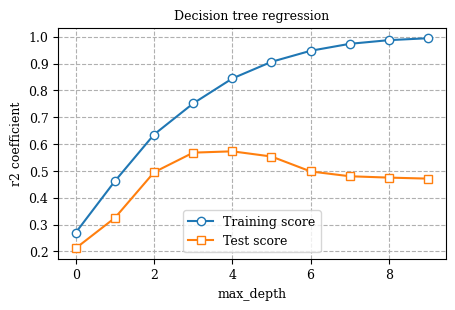

In [9]:
fig, ax = plt.subplots(figsize=(5,3))
ax.plot(mean_train_scores, marker = "o", markerfacecolor='white', label = "Training score")
ax.plot(mean_test_scores, marker = "s", markerfacecolor='white', label = "Test score")
ax.set_title('Decision tree regression')
ax.set_xlabel('max_depth')
ax.set_ylabel('r2 coefficient')
ax.legend(loc="lower center")
plt.grid(linestyle = "--")
plt.show()

Veámolo con otro ejemplo, en este caso con las conocidas máquinas de soporte vectorial (SVM). En estos modelos se busca el equilibrio entre le regularización y el ajuste (trade off between regularization and fit). El término de regularización mide la planitud (flatness) del modelo, lo que puede interpretase como la simplicidad del modelo, al definir una frontera dedecisión menos sinuosa, mas aplanada. Por tanto, el minimiza el parámetro de regularización se construye un modelo mas simpple, que si bien tiene menorajsute a lo datos de entrenamiento, puede generalizar mejor.

In [10]:
# Probemos con SVM

from sklearn.svm import SVR

model = SVR(kernel = "rbf", gamma = 0.1)

trn_scores, tst_scores = validation_curve(estimator = model,
                                          X=X,
                                          y=y,
                                          param_name= 'C',
                                          param_range= np.logspace(-2,4,7),
                                          cv=subsets, scoring="r2")

mean_train_scores = np.mean(trn_scores, axis=1)
mean_test_scores = np.mean(tst_scores, axis=1)

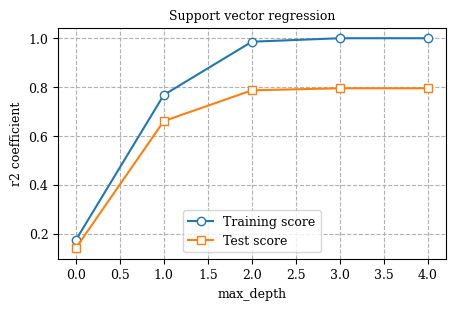

In [20]:
fig, ax = plt.subplots(figsize=(5,3))
ax.plot(mean_train_scores, marker = "o", markerfacecolor='white', label = "Training score")
ax.plot(mean_test_scores, marker = "s", markerfacecolor='white', label = "Test score")
ax.set_title('Support vector regression')
ax.set_xlabel('max_depth')
ax.set_ylabel('r2 coefficient')
ax.legend(loc="lower center")
plt.grid(linestyle = "--")
plt.show()

Al igual que en los arboles de decisión, el modelo que mejor rendimiento exhibe no es elque mejos sesjusta al conjunto de entrenamiento. De hecho, todos los algorimos de machine learning exhiben este comportammiento:
1. Modelos demasiado simples no aprenden bien del proceso generador de datos, por lo que no generalizarán adecuadamente. Esto se conoce como sub-ajuste o underfitting.
2. Modelos muy complejos pueden ajustarse adecuadamente al conjunto de entrenamiento, pero exhibir un mal rendimiento ante datos no observados. Esto se conoce como sobreajuste o overfitting.
3. Los mejores modelos compensan entre complejidad y ajuste, sacrificando un poco de cada uno para que puedan generalizar mejor.

Los modelos de ensamble son métodos eficaces para abordasr el problemna entre ajuste y complejidad, sesgo y varianza.

Recuérdese: modelos con alta complejidad o bajo sesgo,son muy sensibles al ruido, exhibiendo alta varianza. Los modelos mas simples son sensibles al sesgo, pero menos sensible al ruuido, es decir, baja varianza.

## Modelos de ensamble

 hasta ahora hemos visto como apartir de un conjunto de entrenamiento conseguimos un conjunto de estimadores base (set of base estimators) tambié conocidos como base learners. Usando diversos algoritmos, podemos producir una diversidad de conjuntos de estimadores base. Estos estimadores base podrían agregarse a través de un promedio simple para fomrar una predicción final final ensamble prediction.

 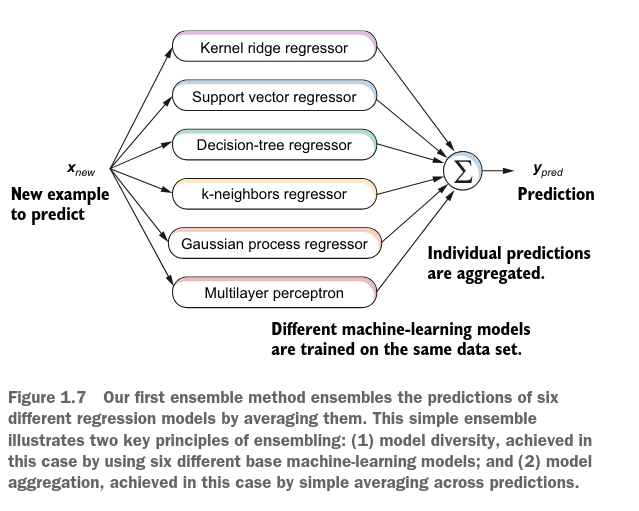
